# Physics-Informed Neural Networks: Reading the Soil's Thermometer

Run it top to bottom. Every figure is produced here and saved in `images/`.

**Data (real):** hourly soil temperatures at 5, 10, 20, 50 and 100 cm from the U.S. Climate Reference
Network station Nunn 7 NNE, Colorado (NOAA NCEI), 8–28 June 2023, a period without rain.

## Setup

In [1]:
# Python ≥3.8 is required
import sys
assert sys.version_info >= (3, 8)

# PyTorch is required for the neural networks
import torch
torch.set_num_threads(4)

# Common imports
import os
import time
import numpy as np
import pandas as pd

# To make this notebook's output stable across runs
np.random.seed(42)
torch.manual_seed(42)

# To plot pretty figures
import matplotlib as mpl
import matplotlib.pyplot as plt
mpl.rc('axes', labelsize=13)
mpl.rc('xtick', labelsize=11)
mpl.rc('ytick', labelsize=11)

# Where to save the figures and the data
PROJECT_ROOT_DIR = "."
IMAGES_PATH = os.path.join(PROJECT_ROOT_DIR, "images")
DATA_PATH = os.path.join(PROJECT_ROOT_DIR, "datasets", "uscrn")
os.makedirs(IMAGES_PATH, exist_ok=True)
os.makedirs(DATA_PATH, exist_ok=True)

def save_fig(fig_id, tight_layout=True, fig_extension="png", resolution=150):
    path = os.path.join(IMAGES_PATH, fig_id + "." + fig_extension)
    print("Saving figure", fig_id)
    if tight_layout:
        plt.tight_layout()
    plt.savefig(path, format=fig_extension, dpi=resolution)

## Get the Data

In [2]:
import urllib.request

USCRN = "https://www.ncei.noaa.gov/pub/data/uscrn/products/hourly02/"
STATION = "CO_Nunn_7_NNE"

def fetch_uscrn(station=STATION, year=2023):
    path = os.path.join(DATA_PATH, f"CRNH0203-{year}-{station}.txt")
    header = os.path.join(DATA_PATH, "HEADERS.txt")
    if not os.path.exists(path):
        urllib.request.urlretrieve(f"{USCRN}{year}/CRNH0203-{year}-{station}.txt", path)
        urllib.request.urlretrieve(USCRN + "HEADERS.txt", header)
    cols = open(header).read().splitlines()[1].split()
    df = pd.read_csv(path, sep=r"\s+", header=None, names=cols, dtype={"LST_DATE": str, "LST_TIME": str})
    df["time"] = pd.to_datetime(df.LST_DATE + df.LST_TIME.str.zfill(4), format="%Y%m%d%H%M")
    return df.set_index("time").replace([-9999.0, -99.0], np.nan)

raw = fetch_uscrn()
DEPTHS = [5, 10, 20, 50, 100]                       # cm
SOIL = [f"SOIL_TEMP_{d}" for d in DEPTHS]
raw[["T_HR_AVG", "P_CALC", "SOLARAD"] + SOIL].head()

,T_HR_AVG,P_CALC,SOLARAD,SOIL_TEMP_5,SOIL_TEMP_10,SOIL_TEMP_20,SOIL_TEMP_50,SOIL_TEMP_100
time,,,,,,,,
2022-12-31 18:00:00,4.5,0.0,0,-0.4,-0.2,0.1,1.1,2.6
2022-12-31 19:00:00,4.1,0.0,0,-0.4,-0.2,0.1,1.1,2.6
2022-12-31 20:00:00,3.9,0.0,0,-0.4,-0.1,0.2,1.1,2.6
2022-12-31 21:00:00,3.9,0.0,0,-0.3,-0.1,0.2,1.1,2.6
2022-12-31 22:00:00,4.2,0.0,0,-0.3,-0.1,0.2,1.1,2.5


In [3]:
START, END = "2023-06-08", "2023-06-28 23:00"
soil = raw.loc[START:END, SOIL + ["T_HR_AVG", "P_CALC", "SOLARAD", "SOIL_MOISTURE_10"]]
print(f"{len(soil)} hours, rain in the window: {soil.P_CALC.sum():.1f} mm, missing soil values: "
      f"{soil[SOIL].isna().sum().sum()}")
missing = soil[SOIL].isna().any(axis=1)
print("missing hours:", list(soil.index[missing].strftime("%m-%d %H:%M")))
soil[SOIL] = soil[SOIL].interpolate(method="time", limit=6)     # fill the short gaps linearly in time
soil[SOIL].describe().round(2)

504 hours, rain in the window: 0.0 mm, missing soil values: 20
missing hours: ['06-25 10:00', '06-25 11:00', '06-25 12:00', '06-25 13:00']


,SOIL_TEMP_5,SOIL_TEMP_10,SOIL_TEMP_20,SOIL_TEMP_50,SOIL_TEMP_100
count,504.00,504.00,504.00,504.00,504.00
mean,19.08,18.76,18.26,17.63,15.64
std,3.25,2.15,1.55,1.09,0.70
min,13.40,14.60,15.20,15.70,14.70
25%,16.50,17.10,17.00,16.70,15.10
50%,18.55,18.55,18.26,17.50,15.30
75%,21.50,20.32,19.40,18.50,16.30
max,27.40,24.20,22.20,20.20,17.20


Saving figure soil_series_plot


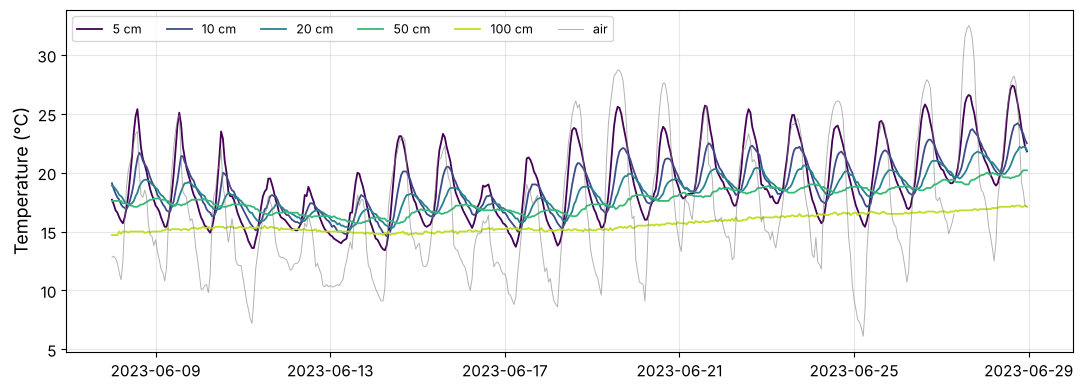

In [4]:
fig, ax = plt.subplots(figsize=(11, 4))
for d, c in zip(DEPTHS, plt.cm.viridis(np.linspace(0, 0.9, 5))):
    ax.plot(soil.index, soil[f"SOIL_TEMP_{d}"], color=c, lw=1.3, label=f"{d} cm")
ax.plot(soil.index, soil.T_HR_AVG, color="gray", lw=0.7, alpha=0.6, label="air")
ax.set_ylabel("Temperature (°C)")
ax.legend(ncol=6, fontsize=9, loc="upper left")
ax.grid(True, alpha=0.3)
save_fig("soil_series_plot")
plt.show()

## The Physics, and the Classical Way to Read It

In [5]:
t_days = ((soil.index - soil.index[0]) / pd.Timedelta("1D")).values
OMEGA = 2 * np.pi                                    # rad per day: the daily cycle

def daily_harmonic(y, t=t_days):
    """Least-squares fit of a + b t + A cos(ωt − φ): returns amplitude A and phase φ (radians)."""
    M = np.c_[np.ones_like(t), t, np.cos(OMEGA * t), np.sin(OMEGA * t)]
    c = np.linalg.lstsq(M, y, rcond=None)[0]
    return np.hypot(c[2], c[3]), np.arctan2(c[3], c[2])

amp, phase = zip(*[daily_harmonic(soil[c].values) for c in SOIL])
amp, phase = np.array(amp), np.unwrap(np.array(phase))
harm = pd.DataFrame({"depth_cm": DEPTHS, "amplitude_C": amp, "lag_hours": 24 * (phase - phase[0]) / (2 * np.pi)})
harm.round(3)

,depth_cm,amplitude_C,lag_hours
0,5,3.379,0.000
1,10,1.827,2.332
2,20,0.914,5.137
3,50,0.270,9.971
4,100,0.024,21.530


In [6]:
z = np.array(DEPTHS) / 100                           # m
s_amp = np.polyfit(z[:4], np.log(amp[:4]), 1)[0]     # ln A = const - z / d  (5-50 cm: the daily wave is
s_phi = np.polyfit(z[:4], phase[:4], 1)[0]           # still clearly measurable there)
DAY = 86400.0
alpha_amp = (OMEGA / DAY) / 2 / s_amp ** 2
alpha_phase = (OMEGA / DAY) / 2 / s_phi ** 2
print(f"damping depth from amplitudes: {-100 / s_amp:.1f} cm, from phases: {100 / s_phi:.1f} cm")
print(f"thermal diffusivity: {alpha_amp * 1e7:.2f} (amplitude method) and {alpha_phase * 1e7:.2f} (phase method) x 1e-7 m²/s")

damping depth from amplitudes: 19.0 cm, from phases: 18.3 cm
thermal diffusivity: 13.16 (amplitude method) and 12.21 (phase method) x 1e-7 m²/s


In [7]:
# The same methods applied to each pair of neighbouring sensors: is the soil uniform?
rows = []
for i in range(3):
    dz = z[i + 1] - z[i]
    d_amp = dz / np.log(amp[i] / amp[i + 1])
    d_phi = dz / (phase[i + 1] - phase[i])
    rows.append({"layer": f"{DEPTHS[i]}-{DEPTHS[i + 1]} cm", "damping depth (cm)": 100 * d_amp,
                 "alpha, amplitudes (1e-7)": (OMEGA / DAY) / 2 * d_amp ** 2 * 1e7,
                 "alpha, phases (1e-7)": (OMEGA / DAY) / 2 * d_phi ** 2 * 1e7})
pd.DataFrame(rows).set_index("layer").round(2)

,damping depth (cm),"alpha, amplitudes (1e-7)","alpha, phases (1e-7)"
layer,,,
5-10 cm,8.13,2.40,2.44
10-20 cm,14.44,7.58,6.74
20-50 cm,24.63,22.06,20.44


Saving figure daily_wave_plot


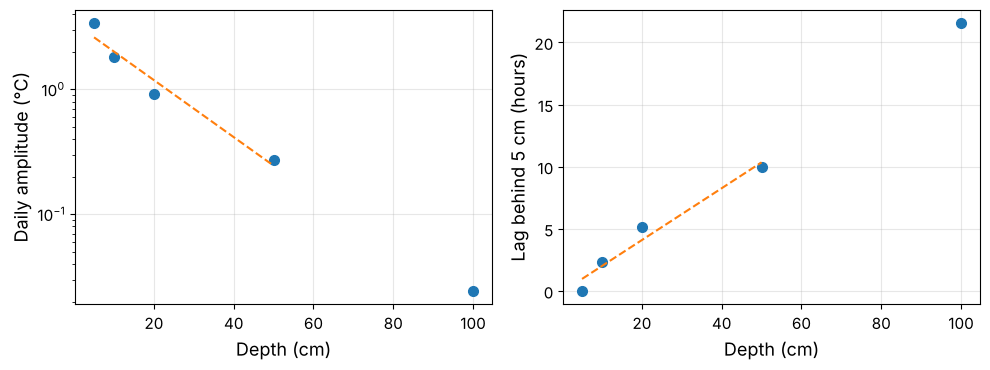

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
zz = np.linspace(0.05, 0.5, 50)
axes[0].semilogy(z * 100, amp, "o", ms=7)
axes[0].semilogy(zz * 100, np.exp(np.polyval(np.polyfit(z[:4], np.log(amp[:4]), 1), zz)), "--")
axes[0].set_xlabel("Depth (cm)"); axes[0].set_ylabel("Daily amplitude (°C)")
axes[1].plot(z * 100, harm.lag_hours, "o", ms=7)
axes[1].plot(zz * 100, 24 * (np.polyval(np.polyfit(z[:4], phase[:4], 1), zz) - phase[0]) / (2 * np.pi), "--")
axes[1].set_xlabel("Depth (cm)"); axes[1].set_ylabel("Lag behind 5 cm (hours)")
for ax in axes:
    ax.grid(True, alpha=0.3)
save_fig("daily_wave_plot")
plt.show()

## A Numerical Simulator, Fitted to the Data

In [9]:
from scipy.interpolate import interp1d

Z_TOP, Z_BOT = 0.05, 1.00                            # the model domain: between the top and bottom sensors
T_top = soil["SOIL_TEMP_5"].values
T_bot = soil["SOIL_TEMP_100"].values
T_obs = soil[SOIL].values                            # hours x depths
t_sec = t_days * DAY

def heat_equation_fd(alpha, nz=96, dt=300.0):
    """Solves dT/dt = alpha d2T/dz2 between 5 and 100 cm (implicit Euler, finite differences),
    with the measured temperatures as boundary conditions. Returns T at every hour and sensor depth."""
    zg = np.linspace(Z_TOP, Z_BOT, nz)
    dz = zg[1] - zg[0]
    T = interp1d(z, T_obs[0])(zg)                    # initial profile: interpolate the sensors
    r = alpha * dt / dz ** 2
    n = nz - 2                                       # interior nodes
    from scipy.linalg import solve_banded
    ab = np.zeros((3, n)); ab[0, 1:] = -r; ab[1, :] = 1 + 2 * r; ab[2, :-1] = -r
    steps = int(round(3600 / dt))
    top = interp1d(t_sec, T_top); bot = interp1d(t_sec, T_bot)
    out = [interp1d(zg, T)(z)]
    t = 0.0
    for k in range(len(t_sec) - 1):
        for _ in range(steps):
            t += dt
            b = T[1:-1].copy()
            T[0], T[-1] = top(t), bot(t)
            b[0] += r * T[0]; b[-1] += r * T[-1]
            T[1:-1] = solve_banded((1, 1), ab, b)
        out.append(interp1d(zg, T)(z))
    return np.array(out)

t0 = time.time()
T_fd = heat_equation_fd(4e-7)
print(f"one simulation of 21 days: {time.time() - t0:.2f} s")

one simulation of 21 days: 0.32 s


In [10]:
from scipy.optimize import minimize_scalar

TRAIN_DEPTHS = [1, 3]                                # 10 cm and 50 cm: used for fitting
TEST_DEPTH = 2                                       # 20 cm: held out to test every method
SPIN = 24                                            # skip the first day (initial-profile guess)

def rmse(a, b):
    return np.sqrt(np.mean((a - b) ** 2))

def fd_loss(log_alpha):
    T = heat_equation_fd(np.exp(log_alpha))
    return rmse(T[SPIN:, TRAIN_DEPTHS], T_obs[SPIN:, TRAIN_DEPTHS])

res = minimize_scalar(fd_loss, bounds=(np.log(5e-8), np.log(3e-6)), method="bounded", options=dict(xatol=1e-3))
alpha_fd = np.exp(res.x)
T_fd = heat_equation_fd(alpha_fd)
print(f"fitted diffusivity: {alpha_fd * 1e7:.2f} x 1e-7 m²/s ({res.nfev} simulations)")
print(f"RMSE at the training depths: {res.fun:.3f} °C,  at 20 cm (held out): "
      f"{rmse(T_fd[SPIN:, TEST_DEPTH], T_obs[SPIN:, TEST_DEPTH]):.3f} °C")
print("RMSE per depth (10, 20, 50 cm):", [round(rmse(T_fd[SPIN:, j], T_obs[SPIN:, j]), 3) for j in (1, 2, 3)])

fitted diffusivity: 5.39 x 1e-7 m²/s (8 simulations)
RMSE at the training depths: 0.521 °C,  at 20 cm (held out): 0.200 °C
RMSE per depth (10, 20, 50 cm): [np.float64(0.466), np.float64(0.2), np.float64(0.571)]


## A Pure Neural Network (No Physics)

In [11]:
# Normalized coordinates: zeta in [0, 1] from 5 to 100 cm, tau in [0, 1] over the 21 days
Z_SCALE, T_SCALE = Z_BOT - Z_TOP, t_sec[-1]
T_MEAN, T_STD = np.nanmean(T_obs), np.nanstd(T_obs)
DATA_DEPTHS = [0, 1, 3, 4]                           # 5, 10, 50, 100 cm (20 cm is held out)

def to_tensor(depth_idx):
    zz, tt = np.meshgrid((z[depth_idx] - Z_TOP) / Z_SCALE, t_sec / T_SCALE)
    X = np.c_[zz.ravel(), tt.ravel()]
    y = ((T_obs[:, depth_idx] - T_MEAN) / T_STD).ravel()
    return torch.tensor(X, dtype=torch.float32), torch.tensor(y[:, None], dtype=torch.float32)

X_data, y_data = to_tensor(DATA_DEPTHS)
X_test, y_test = to_tensor([TEST_DEPTH])
print(X_data.shape, X_test.shape)

torch.Size([2016, 2]) torch.Size([504, 2])


In [12]:
import torch.nn as nn

class FourierMLP(nn.Module):
    """An MLP on (z, t). Time is first encoded with sines and cosines of the daily cycle and its harmonics:
    plain MLPs struggle to learn fast oscillations (spectral bias), and 21 daily cycles are very fast."""
    def __init__(self, n_harmonics=4, width=64, depth=4):
        super().__init__()
        self.register_buffer("k", torch.arange(1, n_harmonics + 1, dtype=torch.float32) * 2 * np.pi * T_SCALE / DAY)
        layers, d_in = [], 2 + 2 * n_harmonics
        for _ in range(depth):
            layers += [nn.Linear(d_in, width), nn.Tanh()]
            d_in = width
        layers.append(nn.Linear(width, 1))
        self.net = nn.Sequential(*layers)
    def forward(self, X):
        zeta, tau = X[:, :1], X[:, 1:2]
        feats = [zeta, tau, torch.sin(self.k * tau), torch.cos(self.k * tau)]
        return self.net(torch.cat(feats, dim=1))

def train_data_only(n_steps=6000, seed=42):
    torch.manual_seed(seed)
    model = FourierMLP()
    opt = torch.optim.Adam(model.parameters(), lr=2e-3)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, n_steps)
    for step in range(n_steps):
        opt.zero_grad()
        loss = torch.mean((model(X_data) - y_data) ** 2)
        loss.backward(); opt.step(); sched.step()
    return model

t0 = time.time()
nn_model = train_data_only()
with torch.no_grad():
    pred_nn = nn_model(X_test).numpy().ravel() * T_STD + T_MEAN
print(f"trained in {time.time() - t0:.0f} s; RMSE at 20 cm (held out): {rmse(pred_nn[SPIN:], T_obs[SPIN:, TEST_DEPTH]):.3f} °C")

trained in 13 s; RMSE at 20 cm (held out): 1.450 °C


## A Physics-Informed Neural Network

In [13]:
class PINN(nn.Module):
    """T(z, t) network plus a learnable thermal diffusivity (log-parametrized)."""
    def __init__(self, alpha0=3e-7, **kw):
        super().__init__()
        self.net = FourierMLP(**kw)
        self.log_alpha = nn.Parameter(torch.tensor(np.log(alpha0), dtype=torch.float32))
    def forward(self, X):
        return self.net(X)
    @property
    def alpha(self):
        return torch.exp(self.log_alpha)
    def residual(self, X, rescale=True):
        """Heat-equation residual dT/dt - alpha d2T/dz2, in normalized units (computed by autograd).
        With rescale=True it is divided by the daily-cycle rate, so that it is of order 1."""
        X = X.clone().requires_grad_(True)
        T = self(X)
        grads = torch.autograd.grad(T.sum(), X, create_graph=True)[0]
        T_z, T_t = grads[:, :1], grads[:, 1:2]
        T_zz = torch.autograd.grad(T_z.sum(), X, create_graph=True)[0][:, :1]
        r = T_t - self.alpha * (T_SCALE / Z_SCALE ** 2) * T_zz
        return r / RATE if rescale else r

RATE = 2 * np.pi * T_SCALE / DAY        # one daily cycle in normalized time: d/dtau ~ RATE x amplitude
print(f"characteristic rate of the daily cycle in normalized time: {RATE:.0f}")

def train_pinn(n_steps=6000, n_colloc=4000, lam=1.0, seed=42, log_every=200, rescale=True):
    torch.manual_seed(seed)
    model = PINN()
    opt = torch.optim.Adam(model.parameters(), lr=2e-3)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, n_steps)
    history = []
    for step in range(n_steps):
        Xc = torch.rand(n_colloc, 2)                             # random collocation points
        opt.zero_grad()
        loss_data = torch.mean((model(X_data) - y_data) ** 2)
        loss_phys = torch.mean(model.residual(Xc, rescale) ** 2)
        loss = loss_data + lam * loss_phys
        loss.backward(); opt.step(); sched.step()
        if step % log_every == 0 or step == n_steps - 1:
            history.append((step, loss_data.item(), loss_phys.item(), model.alpha.item()))
    return model, pd.DataFrame(history, columns=["step", "data_loss", "physics_loss", "alpha"])

# First attempt: the raw residual
t0 = time.time()
pinn_raw, hist_raw = train_pinn(rescale=False)
with torch.no_grad():
    pred_raw = pinn_raw(X_test).numpy().ravel() * T_STD + T_MEAN
print(f"raw residual ({time.time() - t0:.0f} s): alpha = {pinn_raw.alpha.item() * 1e7:.2f} x 1e-7 m²/s, "
      f"RMSE at 20 cm {rmse(pred_raw[SPIN:], T_obs[SPIN:, TEST_DEPTH]):.3f} °C; final losses: "
      f"data {hist_raw.data_loss.iloc[-1]:.4f}, physics {hist_raw.physics_loss.iloc[-1]:.4f}")

characteristic rate of the daily cycle in normalized time: 132


raw residual (105 s): alpha = 1.68 x 1e-7 m²/s, RMSE at 20 cm 1.280 °C; final losses: data 0.6750, physics 0.0436


In [14]:
t0 = time.time()
pinn, hist = train_pinn()
with torch.no_grad():
    pred_pinn = pinn(X_test).numpy().ravel() * T_STD + T_MEAN
print(f"rescaled residual ({time.time() - t0:.0f} s): alpha = {pinn.alpha.item() * 1e7:.2f} x 1e-7 m²/s, "
      f"RMSE at 20 cm {rmse(pred_pinn[SPIN:], T_obs[SPIN:, TEST_DEPTH]):.3f} °C; final losses: "
      f"data {hist.data_loss.iloc[-1]:.4f}, physics {hist.physics_loss.iloc[-1]:.4f}")

rescaled residual (105 s): alpha = 2.34 x 1e-7 m²/s, RMSE at 20 cm 0.456 °C; final losses: data 0.0094, physics 0.0024


Saving figure pinn_training_plot


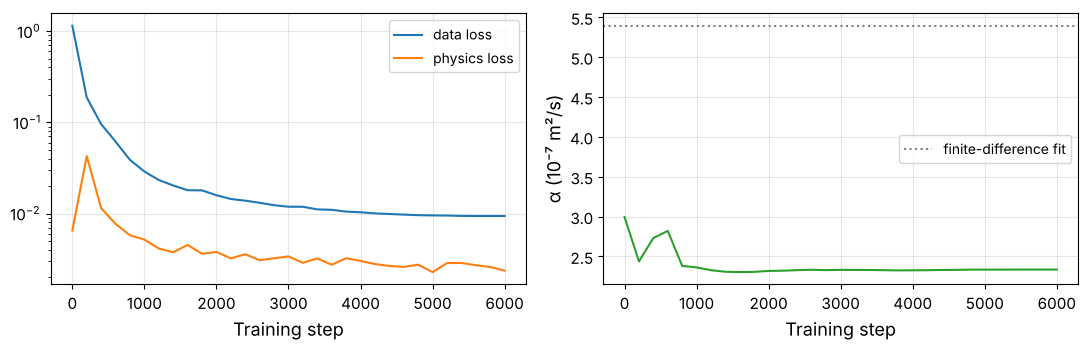

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].semilogy(hist.step, hist.data_loss, label="data loss")
axes[0].semilogy(hist.step, hist.physics_loss, label="physics loss")
axes[0].set_xlabel("Training step"); axes[0].legend()
axes[1].plot(hist.step, hist.alpha * 1e7, "C2")
axes[1].axhline(alpha_fd * 1e7, color="gray", ls=":", label="finite-difference fit")
axes[1].set_xlabel("Training step"); axes[1].set_ylabel("α (10⁻⁷ m²/s)"); axes[1].legend()
for ax in axes:
    ax.grid(True, alpha=0.3)
save_fig("pinn_training_plot")
plt.show()

Saving figure held_out_depth_plot


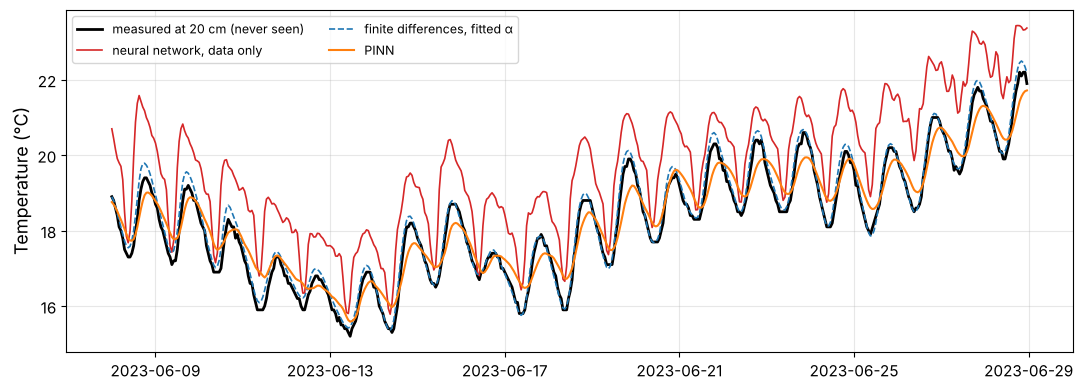

In [16]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(soil.index, T_obs[:, TEST_DEPTH], "k", lw=2, label="measured at 20 cm (never seen)")
ax.plot(soil.index, pred_nn, "C3", lw=1.2, label="neural network, data only")
ax.plot(soil.index, T_fd[:, TEST_DEPTH], "C0--", lw=1.2, label="finite differences, fitted α")
ax.plot(soil.index, pred_pinn, "C1", lw=1.5, label="PINN")
ax.set_ylabel("Temperature (°C)")
ax.legend(ncol=2, fontsize=9, loc="upper left")
ax.grid(True, alpha=0.3)
save_fig("held_out_depth_plot")
plt.show()

In [17]:
rows = []
for lam in (0.0, 0.01, 0.1, 1.0, 10.0):
    m_, _ = train_pinn(n_steps=4000, lam=lam, seed=1)
    with torch.no_grad():
        p_ = m_(X_test).numpy().ravel() * T_STD + T_MEAN
    rows.append(dict(physics_weight=lam, alpha_1e7=m_.alpha.item() * 1e7, rmse_20cm=rmse(p_[SPIN:], T_obs[SPIN:, TEST_DEPTH])))
pd.DataFrame(rows).round(3)

,physics_weight,alpha_1e7,rmse_20cm
0,0.00,3.000,1.254
1,0.01,1.433,0.943
2,0.10,2.162,0.693
3,1.00,2.202,0.537
4,10.00,2.433,0.505


In [18]:
alphas, preds = [], []
t0 = time.time()
for seed in range(5):
    m_, _ = train_pinn(n_steps=4000, seed=100 + seed)
    alphas.append(m_.alpha.item())
    with torch.no_grad():
        preds.append(m_(X_test).numpy().ravel() * T_STD + T_MEAN)
alphas = np.array(alphas)
print(f"5 PINNs in {time.time() - t0:.0f} s: alpha = {alphas.mean() * 1e7:.2f} ± {alphas.std() * 1e7:.2f} x 1e-7 m²/s")
print(f"RMSE at 20 cm of the ensemble mean: {rmse(np.mean(preds, 0)[SPIN:], T_obs[SPIN:, TEST_DEPTH]):.3f} °C")

5 PINNs in 307 s: alpha = 2.28 ± 0.06 x 1e-7 m²/s
RMSE at 20 cm of the ensemble mean: 0.478 °C


In [19]:
summary = pd.DataFrame({
    "alpha (1e-7 m²/s)": [alpha_amp * 1e7, alpha_phase * 1e7, alpha_fd * 1e7, pinn.alpha.item() * 1e7, np.nan],
    "RMSE at 20 cm (°C)": [np.nan, np.nan, rmse(T_fd[SPIN:, TEST_DEPTH], T_obs[SPIN:, TEST_DEPTH]),
                           rmse(pred_pinn[SPIN:], T_obs[SPIN:, TEST_DEPTH]), rmse(pred_nn[SPIN:], T_obs[SPIN:, TEST_DEPTH])]},
    index=["daily wave, amplitudes", "daily wave, phases", "finite differences + fit", "PINN (rescaled residual)", "neural network, data only"])
summary.round(3)

,alpha (1e-7 m²/s),RMSE at 20 cm (°C)
"daily wave, amplitudes",13.162,NaN
"daily wave, phases",12.214,NaN
finite differences + fit,5.394,0.200
PINN (rescaled residual),2.336,0.456
"neural network, data only",NaN,1.450


## Use the PINN: A Continuous Temperature Field and the Ground Heat Flux

Saving figure pinn_field_plot


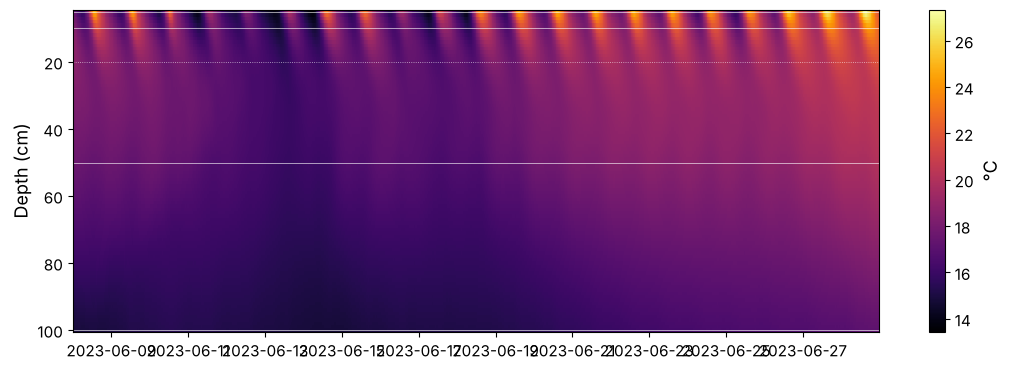

In [20]:
zq = np.linspace(0, 1, 96)
tq = np.linspace(0, 1, 21 * 24 * 2)
ZQ, TQ = np.meshgrid(zq, tq)
Xq = torch.tensor(np.c_[ZQ.ravel(), TQ.ravel()], dtype=torch.float32)
with torch.no_grad():
    field = pinn(Xq).numpy().reshape(len(tq), len(zq)) * T_STD + T_MEAN
fig, ax = plt.subplots(figsize=(11, 3.8))
im = ax.pcolormesh(soil.index[0] + pd.to_timedelta(tq * T_SCALE, unit="s"), 100 * (Z_TOP + zq * Z_SCALE),
                   field.T, cmap="inferno", shading="auto")
for d in DEPTHS:
    ax.axhline(d, color="w", lw=0.6, ls=":" if d == 20 else "-", alpha=0.7)
ax.invert_yaxis()
ax.set_ylabel("Depth (cm)")
fig.colorbar(im, ax=ax, label="°C")
save_fig("pinn_field_plot")
plt.show()

thermal conductivity k = alpha x C = 0.33 W/(m K)
ground heat flux at 5 cm: daily range 45 W/m², peak 44 W/m²; peak solar radiation 993 W/m²
Saving figure ground_heat_flux_plot


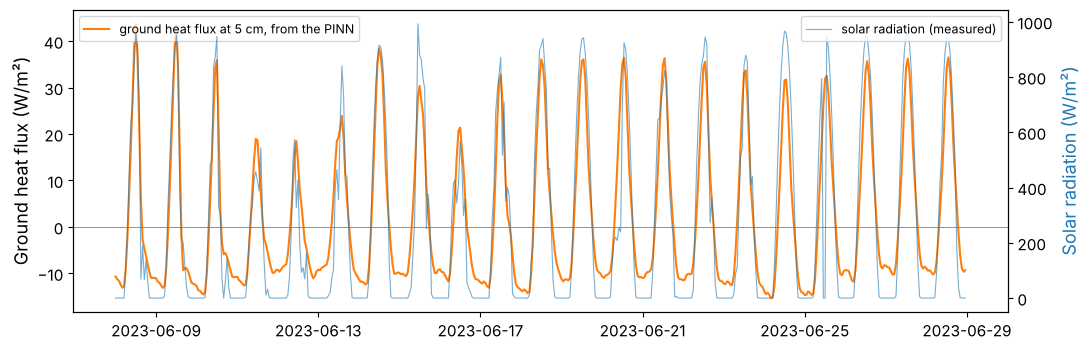

the daily peak of the heat flux at 5 cm lags the peak of the sunshine by 0.2 h


In [21]:
C_SOIL = 1.4e6        # J/(m³ K), a typical volumetric heat capacity for a dry sandy loam
k_soil = pinn.alpha.item() * C_SOIL
Xs = torch.tensor(np.c_[np.zeros_like(t_sec), t_sec / T_SCALE], dtype=torch.float32).requires_grad_(True)
Ts = pinn(Xs)
dT_dz = torch.autograd.grad(Ts.sum(), Xs)[0][:, 0].numpy() * T_STD / Z_SCALE     # °C per m at 5 cm
G = -k_soil * dT_dz                                  # W/m², positive = heat flowing down
print(f"thermal conductivity k = alpha x C = {k_soil:.2f} W/(m K)")
print(f"ground heat flux at 5 cm: daily range {np.mean([G[i:i + 24].max() - G[i:i + 24].min() for i in range(0, 480, 24)]):.0f} W/m², "
      f"peak {G.max():.0f} W/m²; peak solar radiation {soil.SOLARAD.max():.0f} W/m²")
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(soil.index, G, "C1", lw=1.5, label="ground heat flux at 5 cm, from the PINN")
ax2 = ax.twinx()
ax2.plot(soil.index, soil.SOLARAD, "C0", lw=0.8, alpha=0.6, label="solar radiation (measured)")
ax.set_ylabel("Ground heat flux (W/m²)"); ax2.set_ylabel("Solar radiation (W/m²)", color="C0")
ax.axhline(0, color="gray", lw=0.6)
ax.legend(loc="upper left", fontsize=9); ax2.legend(loc="upper right", fontsize=9)
save_fig("ground_heat_flux_plot")
plt.show()
_, ph_G = daily_harmonic(G)
_, ph_S = daily_harmonic(np.nan_to_num(soil.SOLARAD.values))
print(f"the daily peak of the heat flux at 5 cm lags the peak of the sunshine by {24 * ((ph_G - ph_S) % (2 * np.pi)) / (2 * np.pi):.1f} h")

## Launch, Monitor, and Maintain

In [22]:
torch.save(dict(state=pinn.state_dict(), T_mean=T_MEAN, T_std=T_STD, z_top=Z_TOP, z_scale=Z_SCALE,
                t_scale=T_SCALE, start=START), "soil_pinn.pt")
print("saved", os.path.getsize("soil_pinn.pt") // 1024, "KB")

saved 56 KB


In [23]:
import json
os.makedirs("animations", exist_ok=True)
step = 2
anim = dict(
    hours=len(t_sec), depths=DEPTHS, T_obs=np.round(T_obs, 3).tolist(), alpha_fd=alpha_fd, alpha_pinn=pinn.alpha.item(),
    alpha_amp=alpha_amp, alpha_phase=alpha_phase, amp=amp.round(4).tolist(), phase=phase.round(4).tolist(),
    field=np.round(field[::step], 2).tolist(), field_z=(100 * (Z_TOP + zq * Z_SCALE)).round(2).tolist(),
    start=START, pred_nn=np.round(pred_nn, 3).tolist(), pred_pinn=np.round(pred_pinn, 3).tolist())
with open(os.path.join("animations", "data.json"), "w") as f:
    json.dump(anim, f, separators=(",", ":"))
print("exported", os.path.getsize(os.path.join("animations", "data.json")) // 1024, "KB")

exported 300 KB
